In [5]:
#1.__Intialize spark session along with other libraries
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, count, when, unix_timestamp
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql.functions import hour, avg

spark=SparkSession.builder\
      .appName("BigDataPractical1")\
      .getOrCreate()

spark.sparkContext.setLogLevel("ERROR")
print("Spark Session Created Succesfully")

# 2.__load large dataset__
#__replace filepath with your dataset path__
# Upload 'yellow_tripdata_2015-01.csv.zip' to the Colab environment (e.g., to /content/)
# For example, by dragging and dropping it into the files tab on the left sidebar,
# or by using google.colab.files.upload() or mounting Google Drive.
file_path=("/content/yellow_tripdata_2016-03.csv")

df= spark.read.format("csv")\
    .option("header","true")\
    .option("inferSchema","true")\
    .load("/content/yellow_tripdata_2015-01.csv")

print("Schema:")
df.printSchema()

print("Total Rows:",df.count())

#3.__Missing values__

print("\nMissing values Per Column:")

missing_df=df.select([
    count(when(col(c).isNull(),c)).alias(c)
    for c in df.columns
])
missing_df.show()

#Handle Missing Value

#Drop rows where fare_amount or trip_distance is missing
df=df.dropna(subset=["fare_amount","trip_distance"])
#Fill missing passenger_count with median
median_value=df.approxQuantile("passenger_count",[0.5],0.01)[0]
df=df.fillna({"passenger_count":median_value})

print("Missing value handled")

#5.Remove Outliers

#Remove negative or zero values
df=df.filter((col("fare_amount")>0)&
             (col("trip_distance")>0))
#IQR method for fare amount
quantiles=df.approxQuantile("fare_amount",[0.25,0.75],0.01)
Q1,Q3=quantiles
IQR=Q3-Q1

lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.25*IQR

df=df.filter((col("fare_amount")>=lower_bound)&
             (col("fare_amount")<=upper_bound))
print("Outlier removed using IQR.")

#Noise removal (Trip Duration)
df=df.withColumn("trip_duration",unix_timestamp("tpep_dropoff_datetime")-unix_timestamp("tpep_pickup_datetime"))

#Remove invalid trip durations
df=df.filter(col("trip_duration")>0)
print("Noise Handled (invalid durations removed).")

# 7.Parallel Processing Example__
print("\nNumber of Partitions:",df.rdd.getNumPartitions())

#Repartition for better parallelism
df=df.repartition(8)
print("Repartitioned to 8 partitions.")

Spark Session Created Succesfully
Schema:
root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp (nullable = true)
 |-- tpep_dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- pickup_longitude: double (nullable = true)
 |-- pickup_latitude: double (nullable = true)
 |-- RateCodeID: integer (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- dropoff_longitude: double (nullable = true)
 |-- dropoff_latitude: double (nullable = true)
 |-- payment_type: integer (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)

Total Rows: 94236

Missing values Per Column:
+--------+-------------------

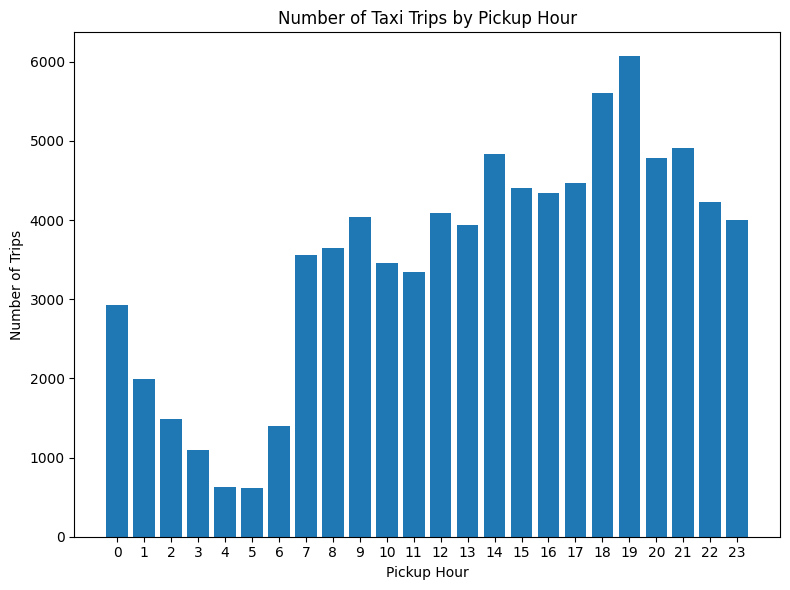

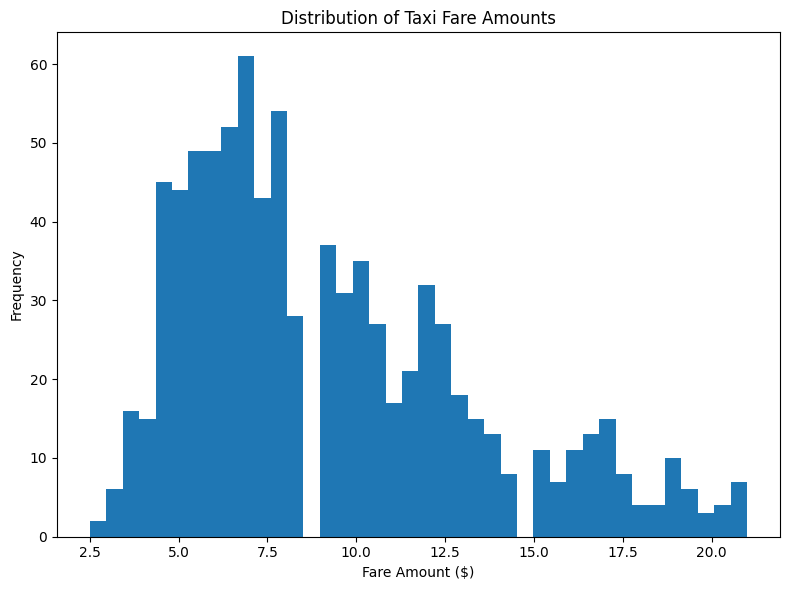

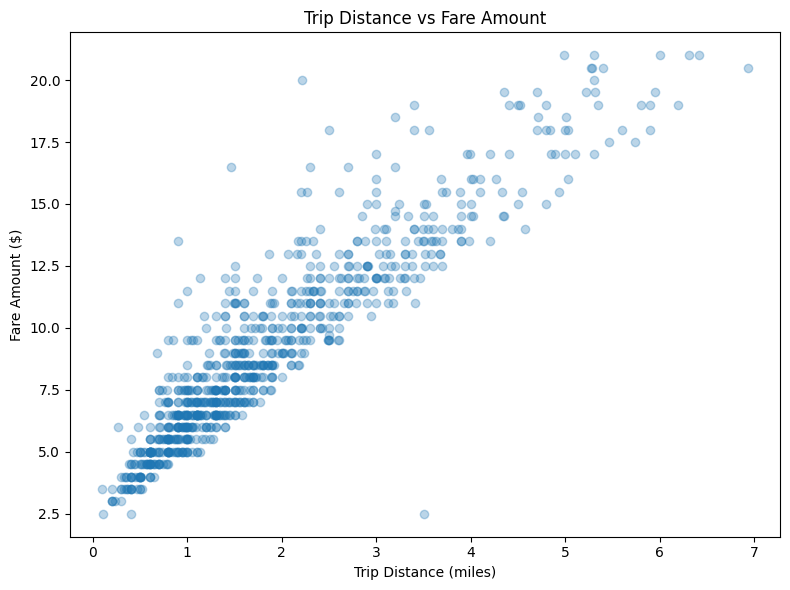

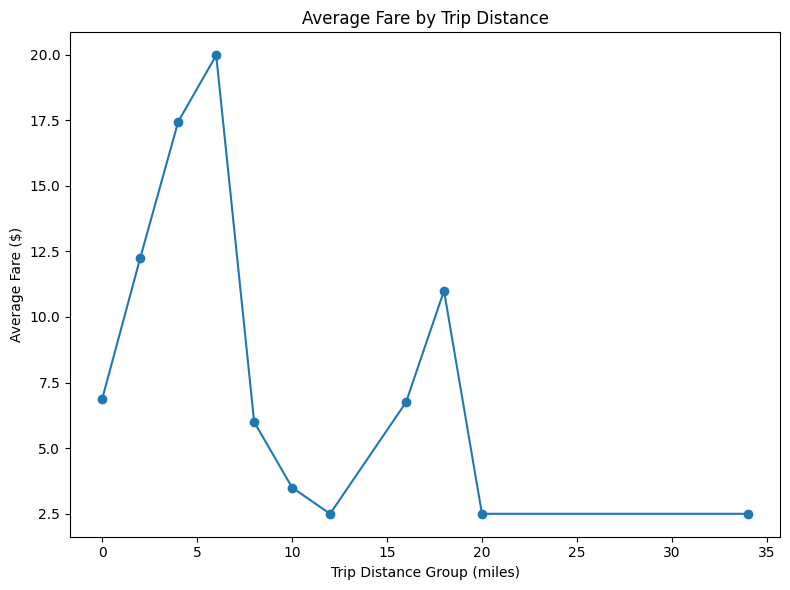

In [6]:
#Visualization
#BY Pickup hours
hourly_trips = (
    df.withColumn("pickup_hour", hour(col("tpep_pickup_datetime")))
      .groupBy("pickup_hour")
      .count()
      .orderBy("pickup_hour")
)

hourly_pd = hourly_trips.toPandas()

plt.figure(figsize=(8, 6))
plt.bar(hourly_pd["pickup_hour"], hourly_pd["count"])
plt.xlabel("Pickup Hour")
plt.ylabel("Number of Trips")
plt.title("Number of Taxi Trips by Pickup Hour")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

#Distribution of fare amounts
fare_pd = (
    df.select("fare_amount")
      .sample(False, 0.01, seed=42)
      .limit(20000)
      .toPandas()
)

plt.figure(figsize=(8, 6))
plt.hist(fare_pd["fare_amount"].dropna(), bins=40)
plt.xlabel("Fare Amount ($)")
plt.ylabel("Frequency")
plt.title("Distribution of Taxi Fare Amounts")
plt.tight_layout()
plt.show()

#Trip distance vs. fare amount
trip_pd = (
    df.select("trip_distance", "fare_amount")
      .sample(False, 0.01, seed=42)
      .limit(20000)
      .toPandas()
)

plt.figure(figsize=(8, 6))
plt.scatter(
    trip_pd["trip_distance"],
    trip_pd["fare_amount"],
    alpha=0.3
)
plt.xlabel("Trip Distance (miles)")
plt.ylabel("Fare Amount ($)")
plt.title("Trip Distance vs Fare Amount")
plt.tight_layout()
plt.show()

#Average fare by trip distance
distance_fare = (
    df.withColumn(
        "distance_group",
        (col("trip_distance") / 2).cast("int") * 2
    )
    .filter(col("distance_group") <= 40)
    .groupBy("distance_group")
    .agg(avg("fare_amount").alias("average_fare"))
    .orderBy("distance_group")
)

distance_pd = distance_fare.toPandas()

plt.figure(figsize=(8, 6))
plt.plot(
    distance_pd["distance_group"],
    distance_pd["average_fare"],
    marker="o"
)
plt.xlabel("Trip Distance Group (miles)")
plt.ylabel("Average Fare ($)")
plt.title("Average Fare by Trip Distance")
plt.tight_layout()
plt.show()